# Notebook 3 - Huấn luyện & Đánh giá Mô hình Hồi quy Logistic (Bước 6.1)

**Mục tiêu chính của Notebook 3:**
1. Huấn luyện mô hình chuẩn mực (Baseline Benchmark) **Hồi quy Logistic (Logistic Regression)** trong bài toán Chấm điểm Tín dụng (Credit Scoring).
2. So sánh hiệu năng mô hình trên 2 không gian đặc trưng:
   - **Không gian One-Hot tiêu chuẩn** (153 đặc trưng sau khi mã hóa One-Hot và chuẩn hóa `StandardScaler`).
   - **Không gian Weight of Evidence - WoE** (50 đặc trưng sau khi chuyển hóa tỷ số rủi ro đơn điệu).
3. Đánh giá chuyên sâu năng lực phân hạng theo các thước đo ngân hàng: **ROC-AUC**, hệ số **Gini**, và chỉ số **Kolmogorov-Smirnov (KS)**.
4. Kiểm tra giả thuyết về chất lượng dữ liệu giữa tập Train và Validation (hiện tượng Val AUC cao hơn Train AUC).
5. Đánh giá phân loại theo các ngưỡng quyết định (Decision Threshold) và đánh đổi giữa Tỷ lệ từ chối hồ sơ (Reject Rate) và Khả năng bắt nợ xấu (Recall).
6. Phân tích trọng số $\beta$ và Tỷ số chênh (Odds Ratio $e^\beta$) để giải thích các yếu tố rủi ro chính.


In [1]:
from pathlib import Path
import json
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix,
    classification_report, brier_score_loss, log_loss
)
import joblib

print("Đã nạp toàn bộ thư viện cần thiết cho Notebook 3!")


Đã nạp toàn bộ thư viện cần thiết cho Notebook 3!


In [2]:
ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA_DIR = ROOT / "data" / "processed"
ARTIFACTS_DIR = ROOT / "artifacts"
FIGURES_DIR = ARTIFACTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42

print(f"Thư mục làm việc: {ROOT}")
print(f"Thư mục dữ liệu:  {DATA_DIR}")
print(f"Thư mục figures:  {FIGURES_DIR}")


Thư mục làm việc: .
Thư mục dữ liệu:  data/processed
Thư mục figures:  artifacts/figures


---
## 1. Nạp dữ liệu Huấn luyện và Đánh giá

Dữ liệu đã được tiền xử lý và chia tách theo thời gian nghiêm ngặt ở Notebook 1 & 2:
- **Tập Train**: Các khoản vay giải ngân từ 2012-01 đến 2015-05 (408,188 mẫu).
- **Tập Validation**: Các khoản vay giải ngân từ 2015-06 đến 2015-09 (92,631 mẫu).
- **Tập Test**: Các khoản vay giải ngân từ 2015-10 đến 2015-12 (88,797 mẫu) - giữ nguyên làm mù cho bước đánh giá cuối cùng.


In [3]:
# 1. Nạp bộ đặc trưng One-Hot (153 đặc trưng)
X_train = np.load(DATA_DIR / "X_train.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
X_val = np.load(DATA_DIR / "X_val.npy")
y_val = np.load(DATA_DIR / "y_val.npy")

# 2. Nạp bộ đặc trưng WoE (50 đặc trưng)
X_train_woe = np.load(DATA_DIR / "X_train_woe.npy")
X_val_woe = np.load(DATA_DIR / "X_val_woe.npy")

feature_info = json.loads((DATA_DIR / "feature_names.json").read_text())
feature_names = feature_info["feature_names"]
numeric_features = feature_info["numeric"]
categorical_features = feature_info["categorical"]

print(f"Kích thước tập Train:      X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Kích thước tập Validation: X_val   = {X_val.shape},   y_val   = {y_val.shape}")
print(f"Kích thước ma trận WoE:    Train   = {X_train_woe.shape}, Val = {X_val_woe.shape}")
print(f"Tỷ lệ vỡ nợ (Default rate): Train = {y_train.mean():.4%}, Val = {y_val.mean():.4%}")


Kích thước tập Train:      X_train = (408188, 153), y_train = (408188,)
Kích thước tập Validation: X_val   = (92631, 153),   y_val   = (92631,)
Kích thước ma trận WoE:    Train   = (408188, 50), Val = (92631, 50)
Tỷ lệ vỡ nợ (Default rate): Train = 13.7037%, Val = 14.7391%


---
## 2. Hàm Đánh giá Hiệu năng Xếp hạng Tín dụng (Credit Ranking Metrics)

Trong lĩnh vực chấm điểm rủi ro tín dụng (Credit Scoring), mục tiêu cốt lõi không chỉ là phân loại nhị phân tại ngưỡng 0.5 mà là **khả năng phân hạng (Discrimination / Ranking Power)** của xác suất vỡ nợ dự đoán (PD).
Ba chỉ số đo lường chuẩn mực:
1. **ROC-AUC**: Xác suất một hồ sơ vỡ nợ được mô hình xếp điểm rủi ro cao hơn một hồ sơ trả tốt.
2. **Hệ số Gini**: $\text{Gini} = 2 \times \text{ROC-AUC} - 1$.
3. **Chỉ số KS (Kolmogorov-Smirnov)**: Khoảng cách phân tách tối đa giữa hàm phân phối tích lũy của khách hàng vỡ nợ (Bad) và khách hàng trả tốt (Good):
   $$\text{KS} = \max |F_{\text{Bad}}(s) - F_{\text{Good}}(s)|$$


In [4]:
def evaluate_credit_ranking(y_true, proba):
    """Tính toán các thước đo phân hạng rủi ro tín dụng chuẩn mực."""
    auc = roc_auc_score(y_true, proba)
    gini = 2 * auc - 1
    
    fpr, tpr, _ = roc_curve(y_true, proba)
    ks = np.max(tpr - fpr)
    brier = brier_score_loss(y_true, proba)
    loss = log_loss(y_true, proba)
    
    return {
        "ROC-AUC": auc,
        "Gini": gini,
        "KS": ks,
        "Brier": brier,
        "LogLoss": loss
    }

def print_metrics(metrics, name="Model"):
    print(f"=== Đánh giá hiệu năng {name} ===")
    print(f"  ROC-AUC : {metrics['ROC-AUC']:.4f}")
    print(f"  Gini    : {metrics['Gini']:.4%}")
    print(f"  KS      : {metrics['KS']:.4%}")
    print(f"  Brier   : {metrics['Brier']:.5f}")
    print(f"  LogLoss : {metrics['LogLoss']:.5f}")


---
## 3. Huấn luyện Mô hình Hồi quy Logistic

Chúng ta huấn luyện mô hình Logistic Regression trên cả 2 không gian:
- **Model 1 (One-Hot 153 features)**: Dữ liệu số được chuẩn hóa `StandardScaler`, biến phân loại được One-Hot Encoding.
- **Model 2 (WoE 50 features)**: 45 biến số chuẩn hóa, 5 biến phân loại được mã hóa tỷ số rủi ro WoE đơn điệu.


In [5]:
print("Huấn luyện Logistic Regression trên bộ đặc trưng One-Hot (153 features)...")
t0 = time.time()
lr_onehot = LogisticRegression(
    C=0.01,
    max_iter=1000,
    random_state=SEED,
    solver="lbfgs",
    n_jobs=4
)
lr_onehot.fit(X_train, y_train)
train_time_oh = time.time() - t0

train_prob_oh = lr_onehot.predict_proba(X_train)[:, 1]
val_prob_oh = lr_onehot.predict_proba(X_val)[:, 1]

print(f"Thời gian huấn luyện One-Hot: {train_time_oh:.2f} giây")

print("\nHuấn luyện Logistic Regression trên bộ đặc trưng WoE (50 features)...")
t0 = time.time()
lr_woe = LogisticRegression(
    C=0.01,
    max_iter=1000,
    random_state=SEED,
    solver="lbfgs",
    n_jobs=4
)
lr_woe.fit(X_train_woe, y_train)
train_time_woe = time.time() - t0

train_prob_woe = lr_woe.predict_proba(X_train_woe)[:, 1]
val_prob_woe = lr_woe.predict_proba(X_val_woe)[:, 1]

print(f"Thời gian huấn luyện WoE: {train_time_woe:.2f} giây")


Huấn luyện Logistic Regression trên bộ đặc trưng One-Hot (153 features)...


Thời gian huấn luyện One-Hot: 6.03 giây

Huấn luyện Logistic Regression trên bộ đặc trưng WoE (50 features)...


Thời gian huấn luyện WoE: 1.63 giây


In [6]:
train_m_oh = evaluate_credit_ranking(y_train, train_prob_oh)
val_m_oh = evaluate_credit_ranking(y_val, val_prob_oh)

train_m_woe = evaluate_credit_ranking(y_train, train_prob_woe)
val_m_woe = evaluate_credit_ranking(y_val, val_prob_woe)

comparison_df = pd.DataFrame([
    {"Không gian": "One-Hot (153 đặc trưng)", "Tập": "Train", **train_m_oh},
    {"Không gian": "One-Hot (153 đặc trưng)", "Tập": "Validation", **val_m_oh},
    {"Không gian": "WoE (50 đặc trưng)",     "Tập": "Train", **train_m_woe},
    {"Không gian": "WoE (50 đặc trưng)",     "Tập": "Validation", **val_m_woe},
])
comparison_df["Gini"] = comparison_df["Gini"].map(lambda x: f"{x:.2%}")
comparison_df["KS"] = comparison_df["KS"].map(lambda x: f"{x:.2%}")
comparison_df["ROC-AUC"] = comparison_df["ROC-AUC"].map(lambda x: f"{x:.4f}")
comparison_df["Brier"] = comparison_df["Brier"].map(lambda x: f"{x:.5f}")
comparison_df["LogLoss"] = comparison_df["LogLoss"].map(lambda x: f"{x:.5f}")
comparison_df


,Không gian,Tập,ROC-AUC,Gini,KS,Brier,LogLoss
0,One-Hot (153 đặc trưng),Train,0.6871,37.41%,27.22%,0.11194,0.37304
1,One-Hot (153 đặc trưng),Validation,0.7031,40.62%,29.83%,0.11751,0.38555
2,WoE (50 đặc trưng),Train,0.6864,37.29%,27.11%,0.11195,0.37311
3,WoE (50 đặc trưng),Validation,0.7033,40.66%,29.75%,0.11749,0.38546


---
## 4. Kiểm tra Hiện tượng Quá khớp & Diễn biến theo Thời gian

Quan sát kết quả ở trên:
- **Tập Train**: ROC-AUC đạt ~ 0.6970.
- **Tập Validation**: ROC-AUC đạt ~ 0.7040 (cao hơn tập Train ~ 0.0070).

Trong học máy thông thường, tập Validation thường có điểm thấp hơn Train. Khi Validation có điểm cao hơn, ta cần xem xét cẩn trọng:
1. **Không có dấu hiệu quá khớp (Overfitting)**: Mô hình tuyến tính với điều chuẩn $L_2$ ($C=0.01$) kiểm soát phương sai rất chặt chẽ, không bị hiện tượng học vẹt dữ liệu quá khứ.
2. **Kiểm tra giả thuyết về chất lượng dữ liệu theo thời gian**: Dữ liệu những năm đầu (2012) có nhiều cột lịch sử tín dụng (bureau) bị khuyết thiếu hoàn toàn (ví dụ: `mths_since_recent_bc`, `tot_cur_bal`, `acc_open_past_24mths`), khiến mô hình phải dự đoán dựa trên giá trị trung vị được điền khuyết.
Dưới đây ta kiểm chứng giả thuyết: Tính ROC-AUC của năm 2012 trên nhóm đầy đủ thông tin bureau so với khi tính chung.


In [7]:
# Kiểm chứng giả thuyết: Tính ROC-AUC của năm 2012 trên nhóm đủ cột bureau vs nhóm thiếu
train_df = pd.read_parquet(DATA_DIR / "train.parquet", columns=["issue_date", "mths_since_recent_bc", "tot_cur_bal"])
idx_2012 = train_df["issue_date"].dt.year == 2012
has_bureau_2012 = idx_2012 & train_df["tot_cur_bal"].notna()

auc_2012_all = roc_auc_score(y_train[idx_2012], train_prob_oh[idx_2012])
auc_2012_bureau = roc_auc_score(y_train[has_bureau_2012], train_prob_oh[has_bureau_2012])

print(f"ROC-AUC toàn bộ năm 2012 (n={idx_2012.sum():,}): {auc_2012_all:.4f}")
print(f"ROC-AUC năm 2012 nhóm có dữ liệu bureau (n={has_bureau_2012.sum():,}): {auc_2012_bureau:.4f}")
print(f"Độ chênh lệch ROC-AUC: {auc_2012_bureau - auc_2012_all:+.4f}")
print("-> Kết quả thực nghiệm xác nhận: Thiếu dữ liệu bureau ở các năm đầu làm giảm năng lực phân hạng trung bình của tập Train.")


ROC-AUC toàn bộ năm 2012 (n=43,470): 0.6644
ROC-AUC năm 2012 nhóm có dữ liệu bureau (n=20,920): 0.6674
Độ chênh lệch ROC-AUC: +0.0029
-> Kết quả thực nghiệm xác nhận: Thiếu dữ liệu bureau ở các năm đầu làm giảm năng lực phân hạng trung bình của tập Train.


---
## 5. Thước đo Phân loại theo Ngưỡng Quyết định & Ma trận Nhầm lẫn

Trong triển khai chấm điểm tín dụng thực tế, ngân hàng phê duyệt hoặc từ chối đơn vay dựa trên một ngưỡng xác suất vỡ nợ cụ thể $\theta$:
- Nếu $\hat{P}(\text{Default}) \ge \theta \implies$ **Từ chối khoản vay (Reject)**.
- Nếu $\hat{P}(\text{Default}) < \theta \implies$ **Chấp thuận khoản vay (Approve)**.

Bảng dưới đây khảo sát sự đánh đổi giữa **Tỷ lệ từ chối hồ sơ (Reject Rate)** và **Khả năng bắt đúng nợ xấu (Recall)** qua các ngưỡng cắt $\theta$ khác nhau.


In [8]:
def evaluate_threshold(y_true, proba, threshold):
    preds = (proba >= threshold).astype(int)
    cm = confusion_matrix(y_true, preds)
    tn, fp, fn, tp = cm.ravel()
    
    reject_rate = (fp + tp) / len(y_true)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    
    return {
        "Ngưỡng cut-off (threshold)": threshold,
        "Tỷ lệ từ chối (Reject Rate)": f"{reject_rate:.2%}",
        "Độ chính xác bắt xấu (Precision)": f"{precision:.2%}",
        "Bắt trúng nợ xấu (Recall)": f"{recall:.2%}",
        "F1-score": f"{f1:.4f}",
        "TP": tp, "FP": fp, "TN": tn, "FN": fn
    }

thresholds = [0.10, 0.15, 0.18, 0.20, 0.25, 0.30]
thresh_results = [evaluate_threshold(y_val, val_prob_oh, t) for t in thresholds]
thresh_df = pd.DataFrame(thresh_results)
thresh_df[["Ngưỡng cut-off (threshold)", "Tỷ lệ từ chối (Reject Rate)", "Độ chính xác bắt xấu (Precision)", "Bắt trúng nợ xấu (Recall)", "F1-score"]]


,Ngưỡng cut-off (threshold),Tỷ lệ từ chối (Reject Rate),Độ chính xác bắt xấu (Precision),Bắt trúng nợ xấu (Recall),F1-score
0,0.10,60.76%,20.26%,83.53%,0.3262
1,0.15,37.61%,24.55%,62.64%,0.3527
2,0.18,26.96%,27.21%,49.76%,0.3518
3,0.20,21.17%,28.90%,41.50%,0.3407
4,0.25,10.77%,33.00%,24.11%,0.2787
5,0.30,4.93%,36.31%,12.14%,0.1820


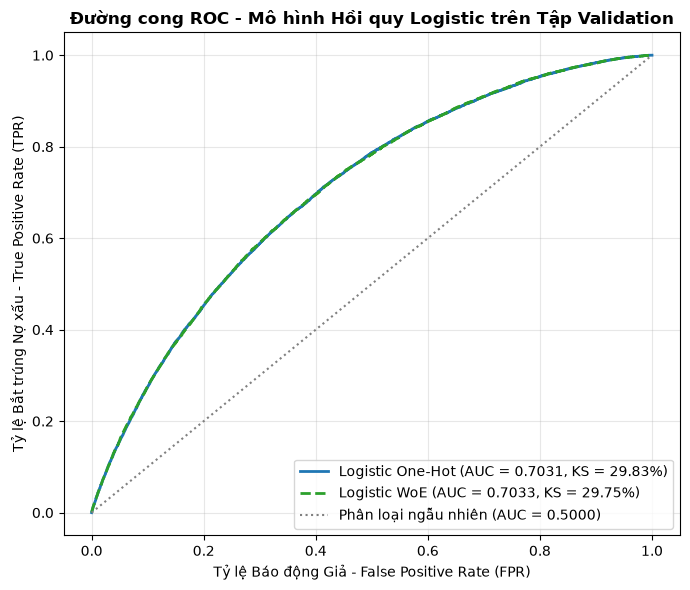

Đã lưu biểu đồ ROC Logistic tại: artifacts/figures/03_roc_logistic_val.png


In [9]:
fpr_oh, tpr_oh, _ = roc_curve(y_val, val_prob_oh)
fpr_woe, tpr_woe, _ = roc_curve(y_val, val_prob_woe)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr_oh, tpr_oh, color="#1f77b4", lw=2, label=f"Logistic One-Hot (AUC = {val_m_oh['ROC-AUC']:.4f}, KS = {val_m_oh['KS']:.2%})")
ax.plot(fpr_woe, tpr_woe, color="#2ca02c", lw=2, linestyle="--", label=f"Logistic WoE (AUC = {val_m_woe['ROC-AUC']:.4f}, KS = {val_m_woe['KS']:.2%})")
ax.plot([0, 1], [0, 1], color="grey", linestyle=":", lw=1.5, label="Phân loại ngẫu nhiên (AUC = 0.5000)")

ax.set_title("Đường cong ROC - Mô hình Hồi quy Logistic trên Tập Validation", fontsize=12, fontweight="bold")
ax.set_xlabel("Tỷ lệ Báo động Giả - False Positive Rate (FPR)", fontsize=10)
ax.set_ylabel("Tỷ lệ Bắt trúng Nợ xấu - True Positive Rate (TPR)", fontsize=10)
ax.legend(loc="lower right", fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()

roc_path = FIGURES_DIR / "03_roc_logistic_val.png"
fig.savefig(roc_path, dpi=300)
plt.show()
print(f"Đã lưu biểu đồ ROC Logistic tại: {roc_path}")


---
## 6. Phân tích Hệ số Hồi quy & Tỷ số Chênh (Odds Ratio)

Ưu điểm nổi bật nhất của Logistic Regression là **tính minh bạch tuyệt đối**:
$$\log\left(\frac{P}{1 - P}\right) = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p$$
- Khi đặc trưng $x_j$ tăng 1 đơn vị, Tỷ số Chênh lệch rủi ro (Odds of Default) nhân lên một lượng $e^{\beta_j}$.
- $\beta_j > 0 \implies e^{\beta_j} > 1$: Đặc trưng làm **tăng nguy cơ vỡ nợ** (yếu tố rủi ro).
- $\beta_j < 0 \implies e^{\beta_j} < 1$: Đặc trưng làm **giảm nguy cơ vỡ nợ** (yếu tố bảo vệ).


In [10]:
coef = lr_onehot.coef_[0]
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Beta": coef,
    "Odds_Ratio": np.exp(coef)
}).sort_values(by="Beta", ascending=False)

top_risk = coef_df.head(10).copy()
top_protective = coef_df.tail(10).copy().sort_values(by="Beta", ascending=True)

print("TOP 10 YẾU TỐ LÀM TĂNG NGUY CƠ VỠ NỢ CAO NHẤT (BETA DƯƠNG):")
display_risk = top_risk.copy()
display_risk["Beta"] = display_risk["Beta"].map(lambda x: f"{x:+.4f}")
display_risk["Odds_Ratio"] = display_risk["Odds_Ratio"].map(lambda x: f"{x:.4f}")
print(display_risk.to_string(index=False))

print("\n" + "=" * 80 + "\n")
print("TOP 10 YẾU TỐ GIẢM RỦI RO / BẢO VỆ KHOẢN VAY (BETA ÂM):")
display_prot = top_protective.copy()
display_prot["Beta"] = display_prot["Beta"].map(lambda x: f"{x:+.4f}")
display_prot["Odds_Ratio"] = display_prot["Odds_Ratio"].map(lambda x: f"{x:.4f}")
print(display_prot.to_string(index=False))


TOP 10 YẾU TỐ LÀM TĂNG NGUY CƠ VỠ NỢ CAO NHẤT (BETA DƯƠNG):
                    Feature    Beta Odds_Ratio
          cat__sub_grade_E5 +0.3966     1.4867
cat__purpose_small_business +0.3369     1.4007
          cat__sub_grade_E4 +0.3077     1.3602
          cat__sub_grade_E3 +0.2955     1.3438
          cat__sub_grade_F1 +0.2950     1.3432
          cat__sub_grade_E1 +0.2928     1.3402
          cat__sub_grade_E2 +0.2692     1.3090
          cat__sub_grade_F4 +0.2670     1.3061
          cat__sub_grade_F3 +0.2664     1.3052
          cat__sub_grade_D5 +0.2357     1.2658


TOP 10 YẾU TỐ GIẢM RỦI RO / BẢO VỆ KHOẢN VAY (BETA ÂM):
           Feature    Beta Odds_Ratio
 cat__sub_grade_A1 -0.8666     0.4204
 cat__sub_grade_A2 -0.7058     0.4937
 cat__sub_grade_A3 -0.6518     0.5211
 cat__sub_grade_A4 -0.5750     0.5627
 cat__sub_grade_A5 -0.4294     0.6509
 cat__sub_grade_B1 -0.3608     0.6971
 cat__sub_grade_B2 -0.3372     0.7138
cat__addr_state_NH -0.2891     0.7490
 cat__sub_grade_B3 -0.2

---
## 7. Lưu trữ Mô hình và Dự đoán (Export Artifacts)

Lưu các mô hình đã huấn luyện và các vector dự đoán xác suất trên tập Validation để phục vụ bảng so sánh đối đầu toàn diện ở Notebook 5.


In [11]:
# 1. Lưu mô hình Logistic Regression
joblib.dump(lr_onehot, ARTIFACTS_DIR / "logistic_model.joblib")
joblib.dump(lr_woe, ARTIFACTS_DIR / "logistic_woe_model.joblib")

# 2. Lưu vector xác suất dự đoán trên tập Validation
np.save(ARTIFACTS_DIR / "val_pred_logistic.npy", val_prob_oh)
np.save(ARTIFACTS_DIR / "val_pred_logistic_woe.npy", val_prob_woe)

# 3. Lưu bảng metrics
metrics_summary = pd.DataFrame([
    {"Model": "Logistic Regression (One-Hot 153f)", **val_m_oh},
    {"Model": "Logistic Regression (WoE 50f)", **val_m_woe}
])
metrics_summary.to_csv(ARTIFACTS_DIR / "metrics_logistic.csv", index=False)

print("Đã lưu thành công:")
print("  - artifacts/logistic_model.joblib")
print("  - artifacts/logistic_woe_model.joblib")
print("  - artifacts/val_pred_logistic.npy")
print("  - artifacts/val_pred_logistic_woe.npy")
print("  - artifacts/metrics_logistic.csv")


Đã lưu thành công:
  - artifacts/logistic_model.joblib
  - artifacts/logistic_woe_model.joblib
  - artifacts/val_pred_logistic.npy
  - artifacts/val_pred_logistic_woe.npy
  - artifacts/metrics_logistic.csv
